# Лабораторная работа №3. Кластеризация и глубокая кластеризация
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение. Краткое описание целей и задач работы

- **Цель работы:** изучить алгоритмы кластеризации, оценить качество разбиения и интерпретировать полученные группы.
- **Постановка задачи:**
  1. Загрузить датасет и описать признаки, пропуски и распределения.
  2. Проверить, есть ли смысл кластеризовать данные, и отделить известные метки от признаков.
  3. Стандартизовать числовые признаки и по матрице рассеивания выбрать методы.
  4. Подобрать число кластеров методом локтя и силуэтом.
  5. Построить K-means и EM-кластеризацию (Gaussian Mixture), посчитать внутренние и внешние метрики.
  6. Проверить, как тип ковариации GMM меняет качество.
  7. Обучить глубокую кластеризацию DEC: автокодировщик и дообучение мягких назначений. Сравнить её с классическими методами.
- **Датасет:** White Wine Quality с Kaggle. Одно наблюдение — один образец белого вина португальского сорта Vinho Verde. Признаки — результаты химического анализа, оценка качества известна отдельно.


In [1]:
from pathlib import Path
import os
import urllib.request

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from scipy.stats import shapiro
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_score,
)
from sklearn.metrics.cluster import pair_confusion_matrix
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
DATA_PATH = DATA_DIR / "winequality-white.csv"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

RANDOM_STATE = 42
TARGET = "quality"
CORR_THRESHOLD = 0.80

FEATURES = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]
LABELS = {
    "fixed acidity": "Фиксированная кислотность",
    "volatile acidity": "Летучая кислотность",
    "citric acid": "Лимонная кислота",
    "residual sugar": "Остаточный сахар",
    "chlorides": "Хлориды",
    "free sulfur dioxide": "Свободный диоксид серы",
    "total sulfur dioxide": "Общий диоксид серы",
    "density": "Плотность",
    "pH": "pH",
    "sulphates": "Сульфаты",
    "alcohol": "Спирт",
    "quality": "Оценка",
}

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 140

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
if not DATA_PATH.exists() or DATA_PATH.stat().st_size == 0:
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH, sep=";")
display(raw.head())
schema = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропуски": raw.isna().sum(),
    "уникальные": raw.nunique(),
})
schema.index = [LABELS.get(name, name) for name in schema.index]
display(schema)
quality_counts = raw[TARGET].value_counts().sort_index()
quality_counts.index = [f"оценка {score}" for score in quality_counts.index]
display(quality_counts.to_frame("число образцов"))
print(f"Наблюдений: {len(raw)}")
print(f"Признаков: {raw.shape[1] - 1}")
print(f"Пропусков всего: {int(raw.isna().sum().sum())}")


Наблюдений: 4898
Признаков: 11
Пропусков всего: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


,тип,пропуски,уникальные
Фиксированная кислотность,float64,0,68
Летучая кислотность,float64,0,125
Лимонная кислота,float64,0,87
Остаточный сахар,float64,0,310
Хлориды,float64,0,160
Свободный диоксид серы,float64,0,132
Общий диоксид серы,float64,0,251
Плотность,float64,0,890
pH,float64,0,103
Сульфаты,float64,0,79


,число образцов
оценка 3,20
оценка 4,163
оценка 5,1457
оценка 6,2198
оценка 7,880
оценка 8,175
оценка 9,5


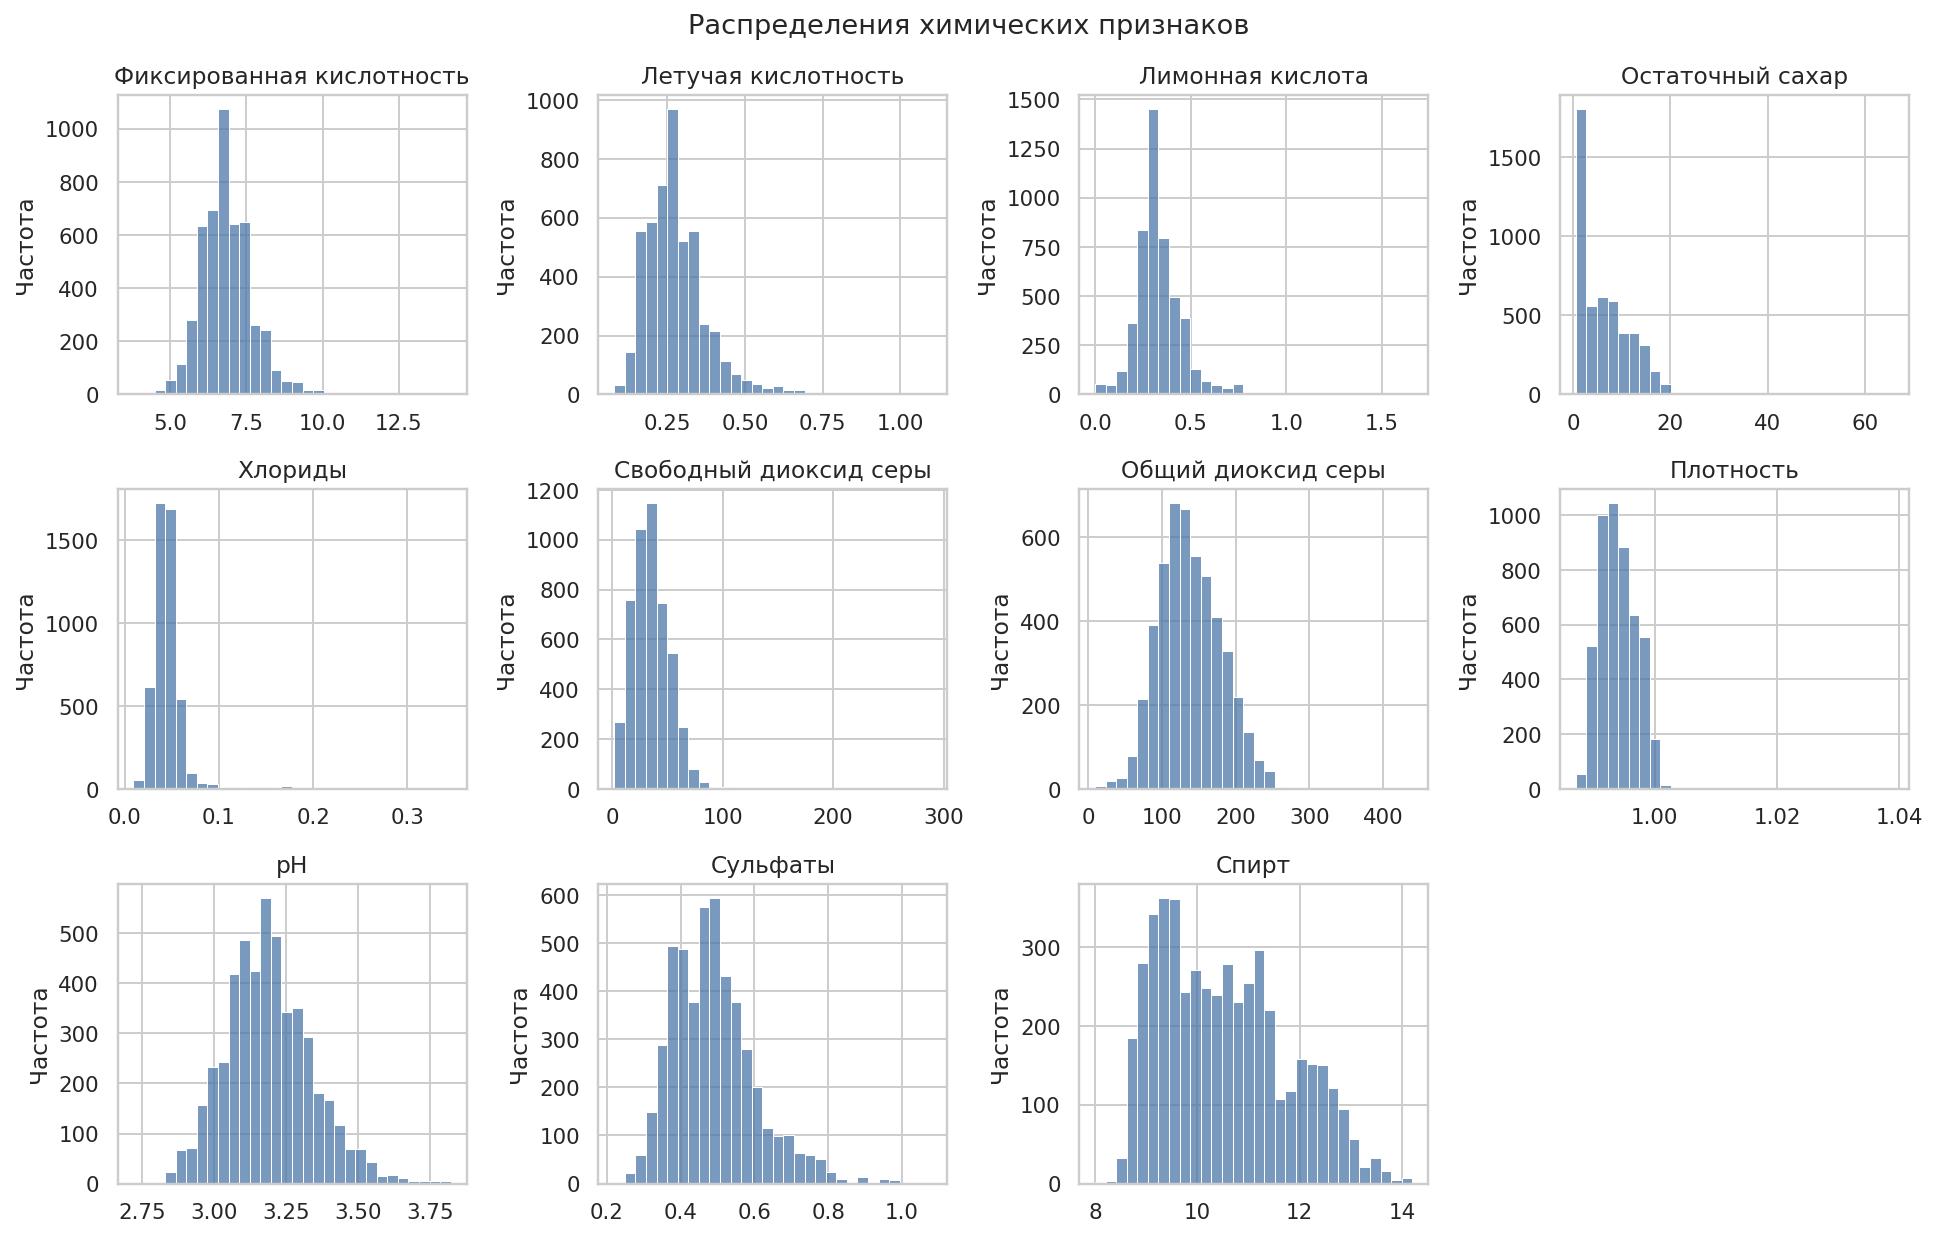

,асимметрия,p-value Шапиро
Признак,,
Фиксированная кислотность,0.648,0.000
Летучая кислотность,1.577,0.000
Лимонная кислота,1.282,0.000
Остаточный сахар,1.077,0.000
Хлориды,5.023,0.000
Свободный диоксид серы,1.407,0.000
Общий диоксид серы,0.391,0.016
Плотность,0.978,0.000
pH,0.458,0.000


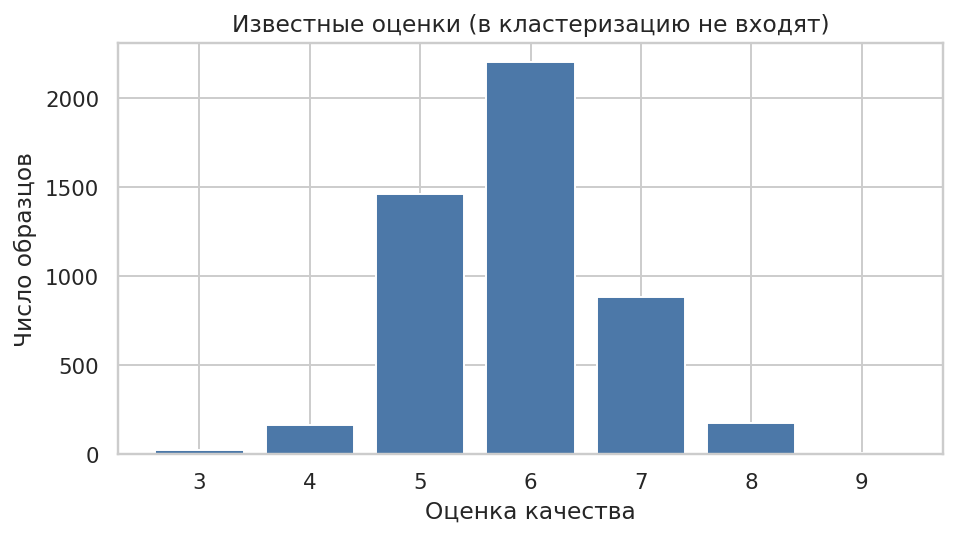

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.histplot(raw[column], bins=30, ax=ax, color="#4C78A8")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
    ax.set_ylabel("Частота")
axes.ravel()[-1].axis("off")
fig.suptitle("Распределения химических признаков", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_histograms.png", bbox_inches="tight")
plt.show()

normality_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for column in FEATURES:
    sample = raw[column].to_numpy()
    if len(sample) > 500:
        sample = rng.choice(sample, size=500, replace=False)
    stat, pvalue = shapiro(sample)
    normality_rows.append({
        "Признак": LABELS[column],
        "асимметрия": float(raw[column].skew()),
        "p-value Шапиро": float(pvalue),
    })
normality = pd.DataFrame(normality_rows).set_index("Признак")
normality.to_csv(OUTPUT_DIR / "normality.csv", encoding="utf-8-sig")
display(normality.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
counts = raw[TARGET].value_counts().sort_index()
ax.bar([str(score) for score in counts.index], counts.values, color="#4C78A8")
ax.set_xlabel("Оценка качества")
ax.set_ylabel("Число образцов")
ax.set_title("Известные оценки (в кластеризацию не входят)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_quality.png", bbox_inches="tight")
plt.show()


### Пояснение к датасету

- **Источник:** White Wine Quality, публикация на Kaggle: https://www.kaggle.com/datasets/piyushagni5/white-wine-quality. Файл сохранён в `data/winequality-white.csv`.
- **Объём:** **4898** образцов и **11** числовых признаков. Пропусков нет (0).
- **Признаки:** фиксированная и летучая кислотность, лимонная кислота, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и спирт.
- **Оценка:** 7 баллов качества, от 3 до 9. Чаще всего встречаются оценки 5 и 6, крайние баллы 3 и 9 редки. Оценка не входит в матрицу признаков и нужна только как внешняя проверка.
- **Нормальность.** Тест Шапиро–Уилка на случайных 500 значениях отвергает нормальность у **11** признаков из 11. Сильнее всего асимметрия у: Хлориды (5,02), Летучая кислотность (1,58), Свободный диоксид серы (1,41). У хлоридов длинный правый хвост.


Строк хотя бы с одним выбросом: 883


,выбросы по IQR
Признак,
Фиксированная кислотность,119
Летучая кислотность,186
Лимонная кислота,270
Остаточный сахар,7
Хлориды,208
Свободный диоксид серы,50
Общий диоксид серы,19
Плотность,5
pH,75


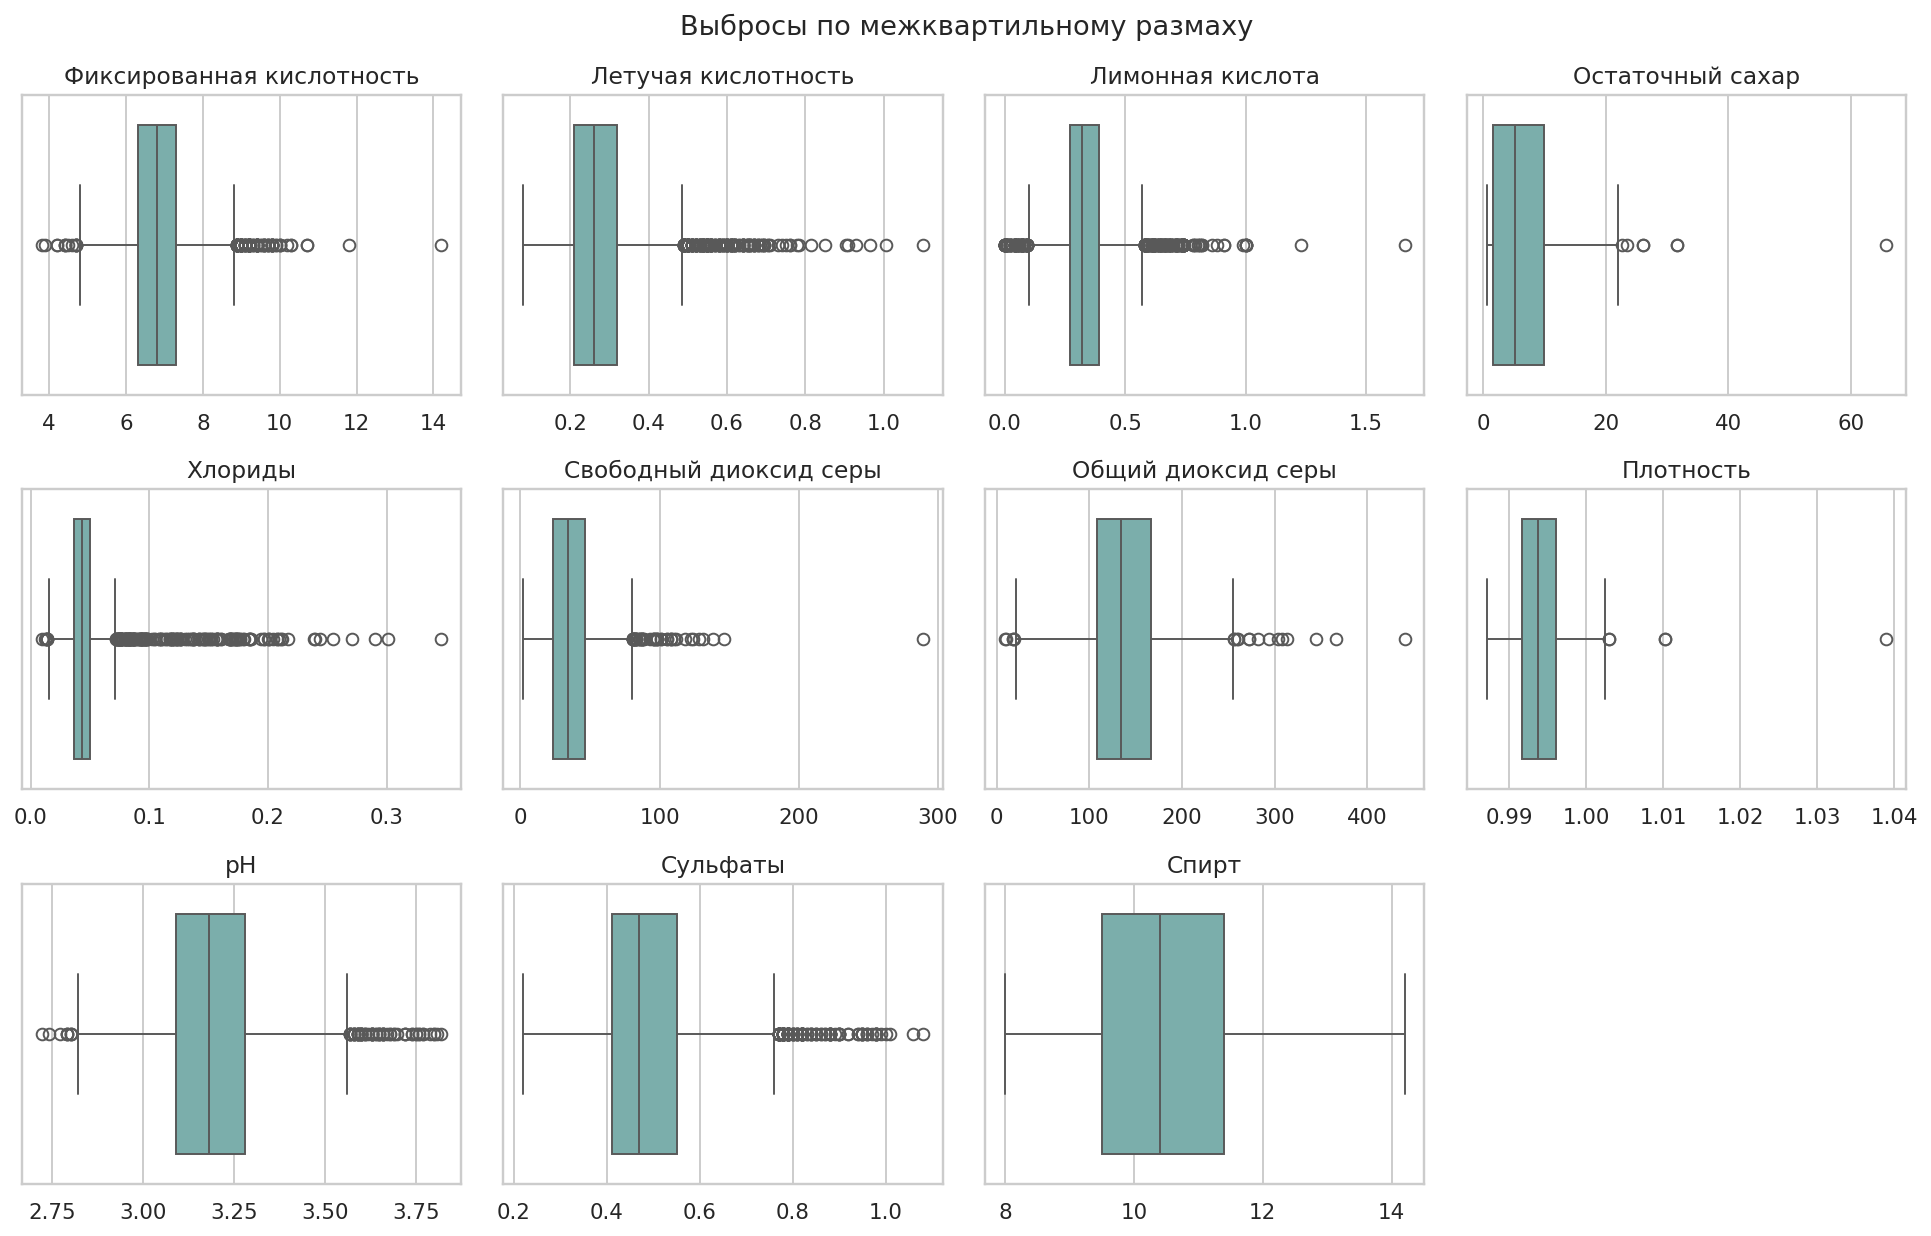

In [4]:
outlier_rows = []
outlier_mask = pd.Series(False, index=raw.index)
for column in FEATURES:
    q1 = raw[column].quantile(0.25)
    q3 = raw[column].quantile(0.75)
    iqr = q3 - q1
    mask = (raw[column] < q1 - 1.5 * iqr) | (raw[column] > q3 + 1.5 * iqr)
    outlier_mask = outlier_mask | mask
    outlier_rows.append({"Признак": LABELS[column], "выбросы по IQR": int(mask.sum())})
outlier_table = pd.DataFrame(outlier_rows).set_index("Признак")
display(outlier_table)
print(f"Строк хотя бы с одним выбросом: {int(outlier_mask.sum())}")

fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=raw[column], ax=ax, color="#72B7B2")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Выбросы по межквартильному размаху", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_boxplots.png", bbox_inches="tight")
plt.show()


### Пояснение к выбросам и условиям кластеризации

- По правилу 1,5 межквартильных размаха хотя бы один необычный признак есть у **883** строк. Больше всего таких значений у признака «Лимонная кислота»: 270. Среди отмеченных строк чаще всего оценка 5 (0,40 доли).
- Эти края относятся к необычным составам, а не к сбою прибора. Строки остаются в выборке: иначе пропадёт часть реальных стилей вина.
- **Условия кластеризации.** В признаки оценка не подаётся, так что алгоритм не видит готовых классов. Группы при этом ожидаемы: вина отличаются сахаром, кислотностью и спиртом. Выбросы по IQR осмысленны как редкие составы, поэтому выборку не чистим.


Удалены как дубли при |r| > 0,80:
- Плотность
Осталось признаков: 10


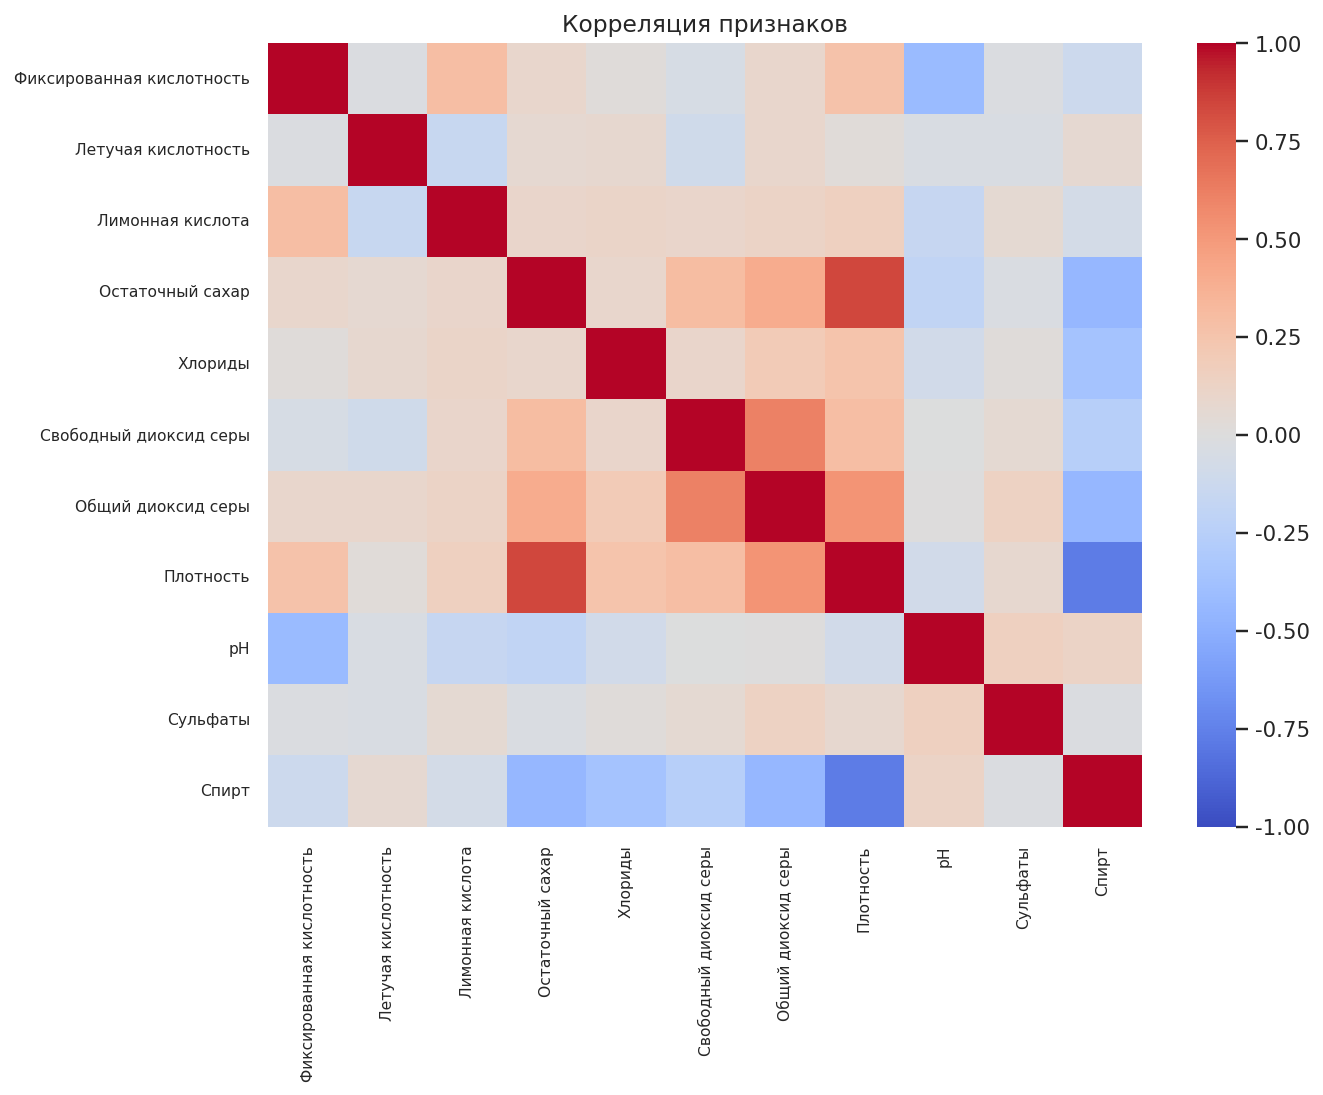

In [5]:
corr = raw[FEATURES].corr()
corr.rename(index=LABELS, columns=LABELS).to_csv(OUTPUT_DIR / "correlation.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr.rename(index=LABELS, columns=LABELS),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
)
ax.tick_params(axis="both", labelsize=8)
ax.set_title("Корреляция признаков")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_correlation.png", bbox_inches="tight")
plt.show()

abs_corr = corr.abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
dropped = [column for column in upper.columns if (upper[column] > CORR_THRESHOLD).any()]
kept = [column for column in FEATURES if column not in dropped]
print("Удалены как дубли при |r| > 0,80:")
for column in dropped:
    print(f"- {LABELS[column]}")
if not dropped:
    print("- нет таких признаков")
print(f"Осталось признаков: {len(kept)}")


### Пояснение к значимости признаков

- Плотность почти повторяет остаточный сахар и спирт: это одна и та же физическая величина, записанная другим способом. Свободный и общий диоксид серы связаны слабее и описывают разные части сернистого состава.
- При пороге |r| > 0,80 из модели убраны: Плотность.
- В кластеризации остаются 10 признаков: Фиксированная кислотность, Летучая кислотность, Лимонная кислота, Остаточный сахар, Хлориды, Свободный диоксид серы, Общий диоксид серы, pH, Сульфаты, Спирт. Так сахар и спирт учитываются напрямую, а плотность не дублирует их в евклидовом расстоянии.


,mean,std
Фиксированная кислотность,-0.0,1.0
Летучая кислотность,0.0,1.0
Лимонная кислота,0.0,1.0
Остаточный сахар,-0.0,1.0
Хлориды,0.0,1.0
Свободный диоксид серы,-0.0,1.0
Общий диоксид серы,-0.0,1.0
pH,-0.0,1.0
Сульфаты,-0.0,1.0
Спирт,-0.0,1.0


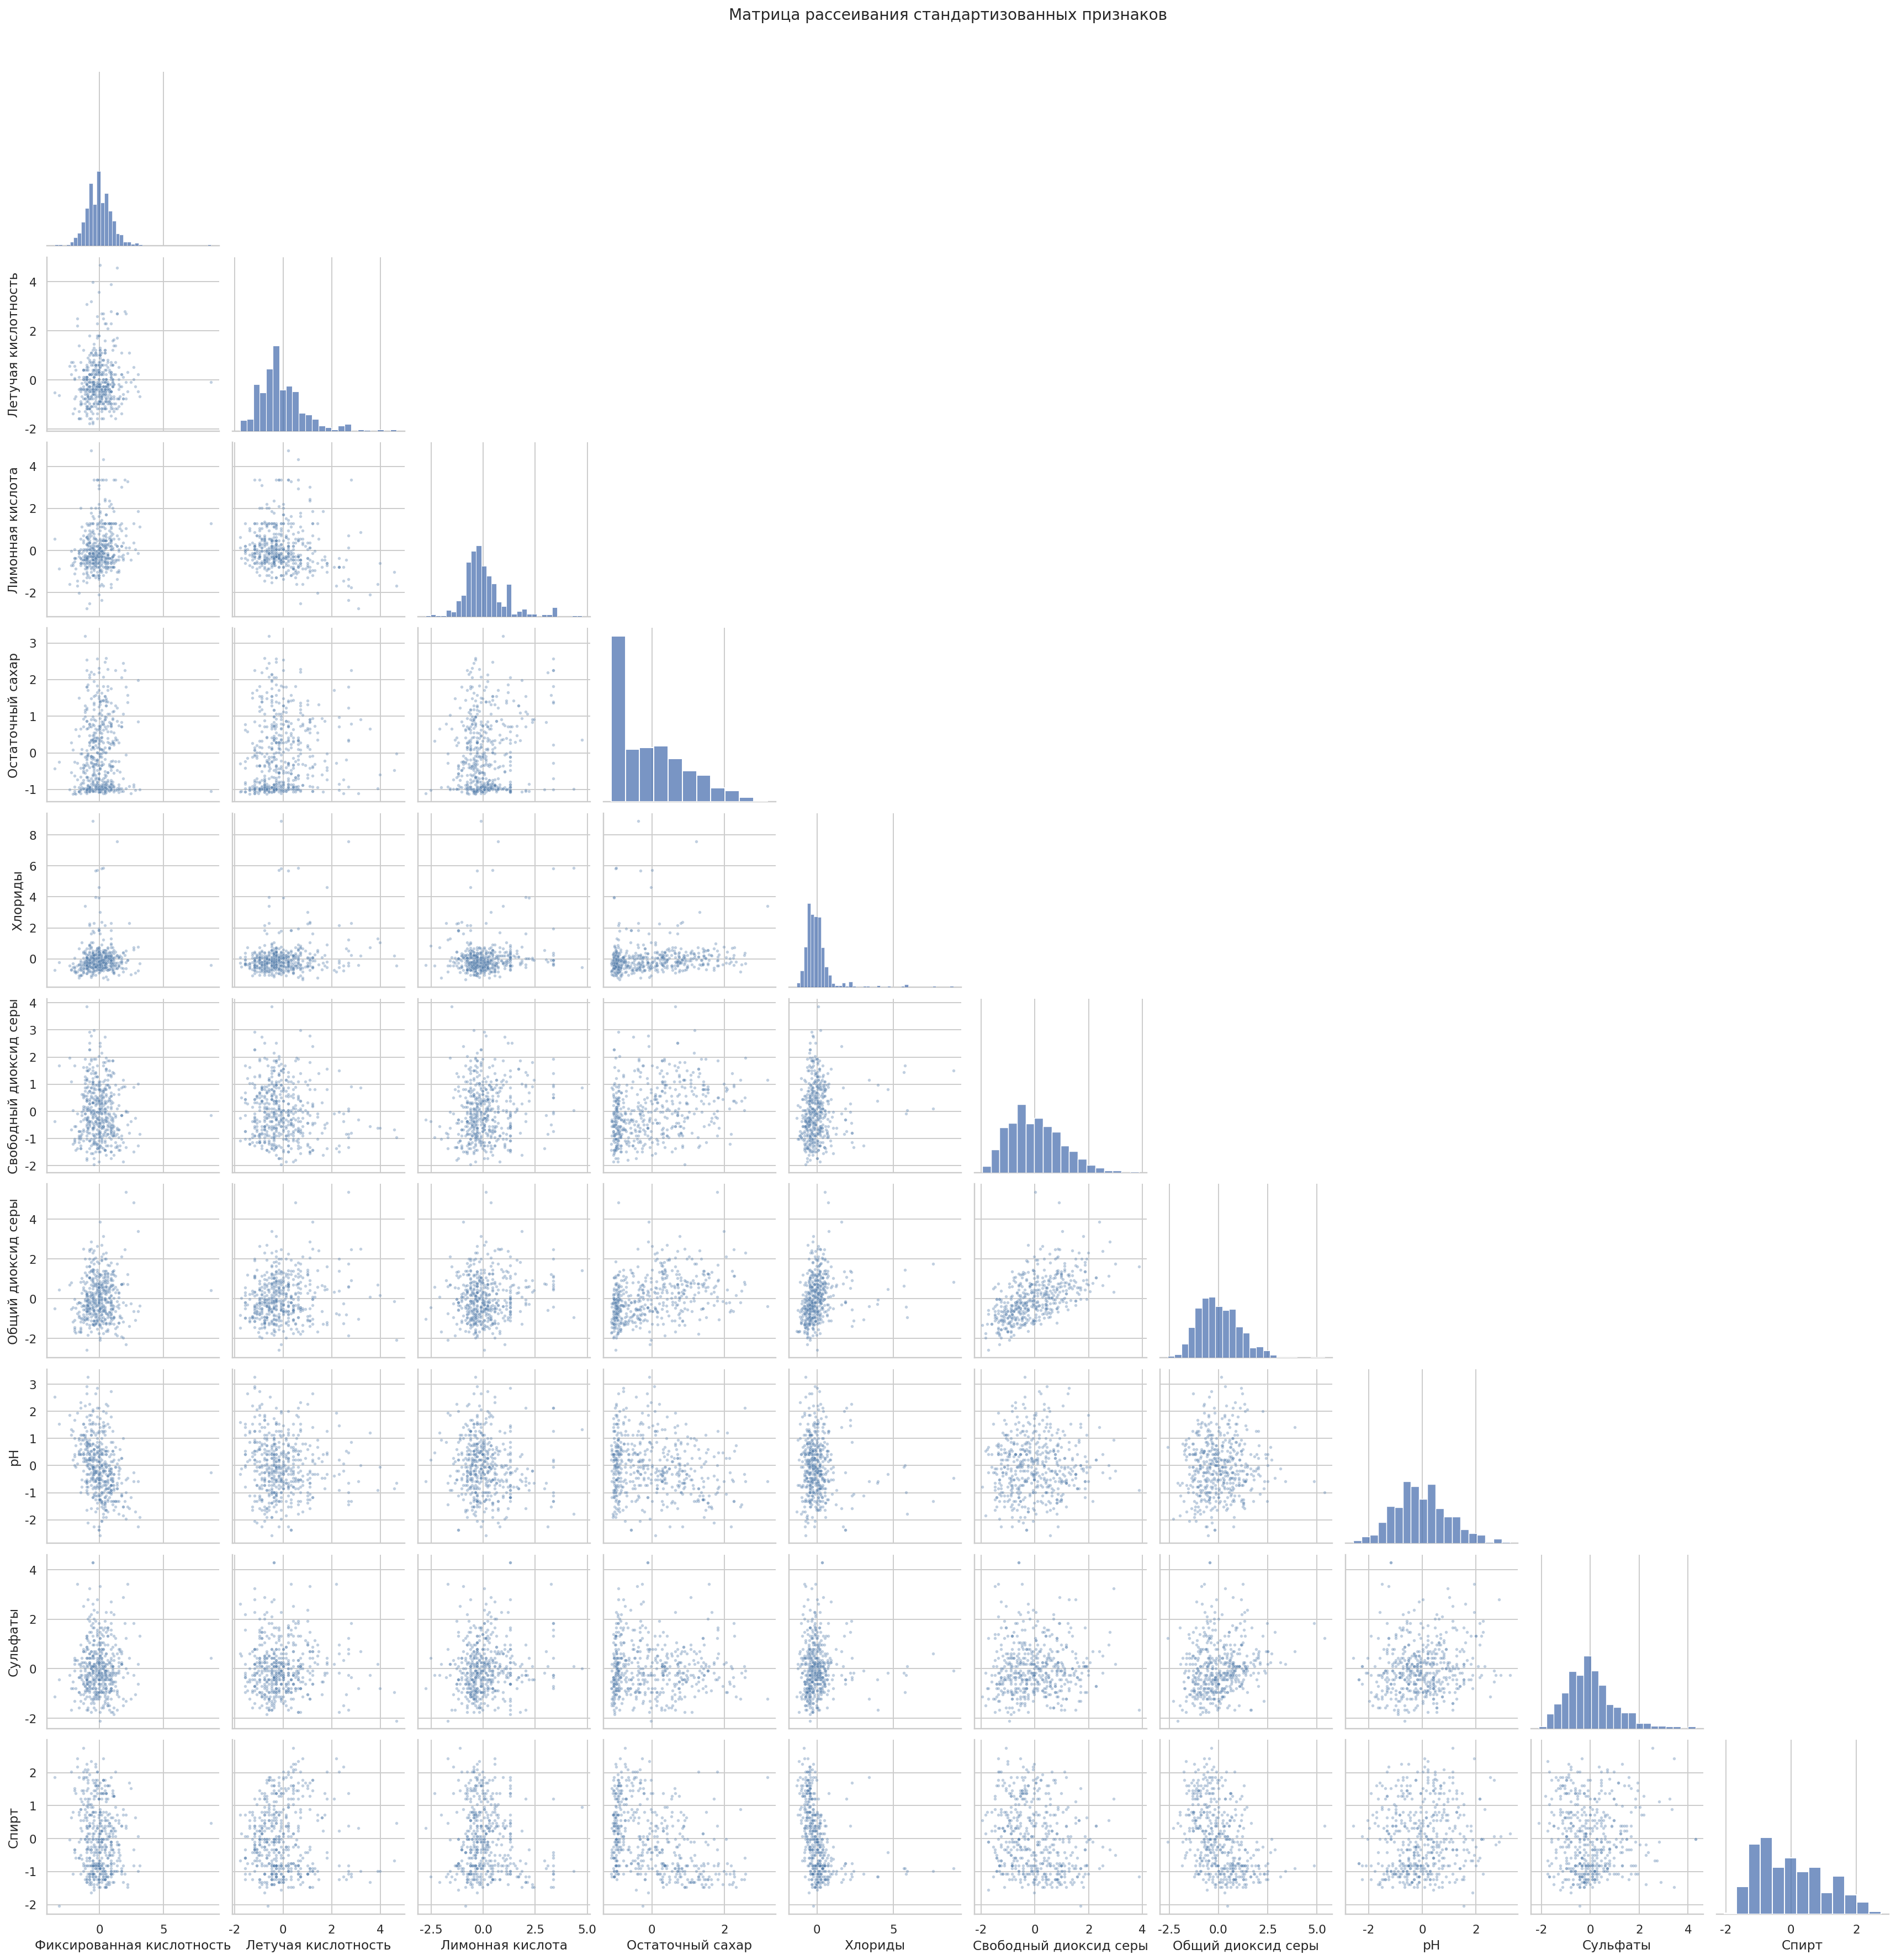

In [6]:
x = raw[kept].copy()
y = raw[TARGET].copy()
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
scaled_frame = pd.DataFrame(x_scaled, columns=kept)
display(scaled_frame.describe().T[["mean", "std"]].rename(index=LABELS).round(3))

plot_frame = scaled_frame.copy()
plot_frame.columns = [LABELS[column] for column in kept]
sample = plot_frame.sample(n=500, random_state=RANDOM_STATE)
grid = sns.pairplot(sample, corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": "#4C78A8"}, diag_kind="hist")
grid.figure.suptitle("Матрица рассеивания стандартизованных признаков", y=1.02)
grid.figure.savefig(OUTPUT_DIR / "05_pairplot.png", bbox_inches="tight")
plt.show()


### Пояснение к масштабированию и матрице рассеивания

- Признаки живут в разных единицах: диоксид серы измеряется десятками и сотнями, плотность лежит около 1, pH около 3, спирт около 10. Евклидово расстояние K-means и GMM без масштаба почти целиком определяется диоксидом серы.
- Выбран **StandardScaler**: после него каждый оставшийся признак имеет среднее 0 и стандартное отклонение 1. MinMax сжал бы все значения в отрезок [0, 1] и оставил бы влияние одного самого сладкого или самого солёного образца на края диапазона. RobustScaler ослабил бы хвост хлоридов; здесь этот хвост — редкий, но настоящий состав, и его полезно сохранить в масштабе стандартного отклонения.
- На матрице рассеивания видны вытянутые облака по сахару и спирту. Группы пересекаются, плотности разные: сухие и сладкие вина не образуют одинаковые шары. Поэтому рядом с K-means берём EM-алгоритм Gaussian Mixture: он допускает эллиптические компоненты и разную ковариацию.


Локоть: k=2
Максимум силуэта: k=2
Выбрано k=2


,k,инерция,силуэт
0,2,40443.965,0.180
1,3,36898.697,0.131
2,4,33880.993,0.149
3,5,31823.219,0.136
4,6,30219.748,0.134
5,7,28789.961,0.121
6,8,27656.007,0.117
7,9,26491.297,0.122
8,10,25757.096,0.115


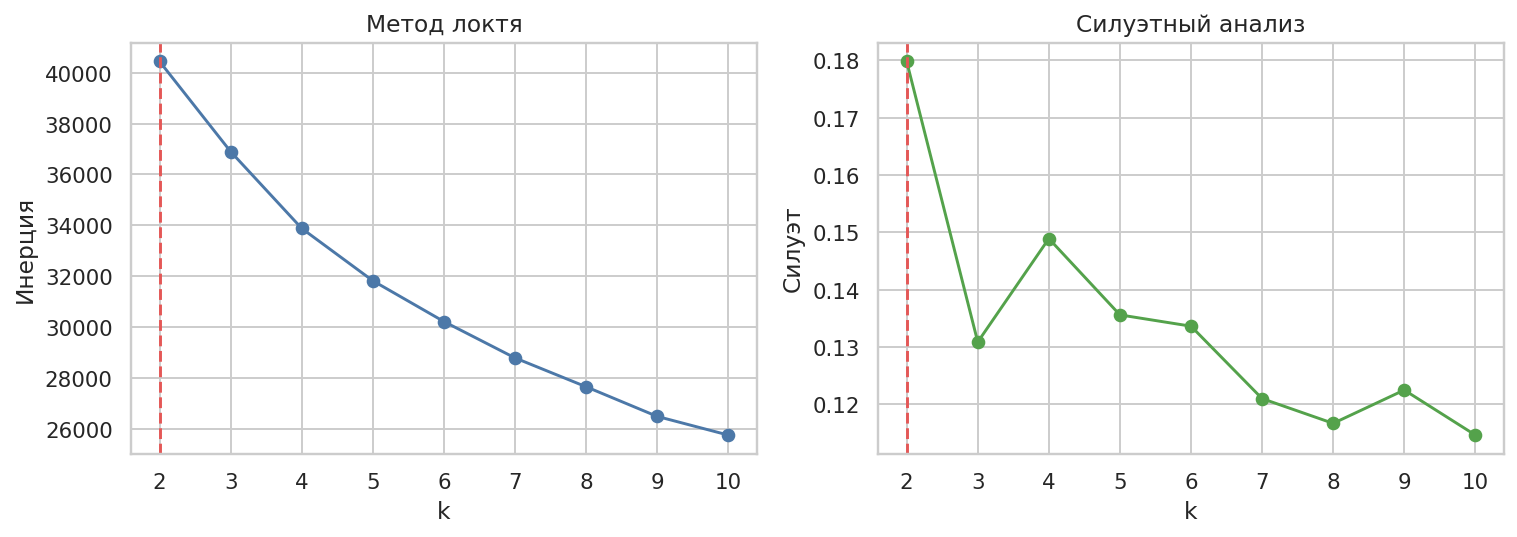

In [7]:
ks = list(range(2, 11))
inertias = []
silhouettes = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(x_scaled)
    inertias.append(float(model.inertia_))
    silhouettes.append(float(silhouette_score(x_scaled, labels, sample_size=2000, random_state=RANDOM_STATE)))

drops = [(inertias[i] - inertias[i + 1]) / inertias[i] for i in range(len(inertias) - 1)]
elbow_k = ks[-1]
for k, drop in zip(ks[:-1], drops):
    if drop < 0.10:
        elbow_k = k
        break
silhouette_k = ks[int(np.argmax(silhouettes))]
if silhouettes[ks.index(silhouette_k)] - silhouettes[ks.index(elbow_k)] < 0.05:
    best_k = elbow_k
else:
    best_k = silhouette_k

k_table = pd.DataFrame({"k": ks, "инерция": inertias, "силуэт": silhouettes})
k_table.to_csv(OUTPUT_DIR / "k_selection.csv", index=False, encoding="utf-8-sig")
display(k_table.round(3))
print(f"Локоть: k={elbow_k}")
print(f"Максимум силуэта: k={silhouette_k}")
print(f"Выбрано k={best_k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o", color="#4C78A8")
axes[0].axvline(best_k, color="#E45756", linestyle="--")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[0].set_title("Метод локтя")
axes[1].plot(ks, silhouettes, marker="o", color="#54A24B")
axes[1].axvline(best_k, color="#E45756", linestyle="--")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Силуэт")
axes[1].set_title("Силуэтный анализ")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_k_selection.png", bbox_inches="tight")
plt.show()


### Пояснение к выбору числа кластеров

- Для k от 2 до 10 посчитаны инерция K-means и силуэт. Силуэт оценивается по случайной подвыборке из 2000 точек, один и тот же датчик для всех k.
- Максимум силуэта приходится на **k = 2** (значение 0,180). У локтя силуэт равен 0,180.
- Локоть определён как первое k, после которого относительное падение инерции становится меньше 0,10. Это **k = 2**.
- В работу берётся **k = 2**. Известные баллы качества на этот выбор не влияют: их семь, и они не совпадают с числом химических групп.


In [8]:
def jaccard_index(y_true, y_pred):
    matrix = pair_confusion_matrix(y_true, y_pred)
    true_negative, false_positive, false_negative, true_positive = matrix.ravel()
    denominator = true_positive + false_positive + false_negative
    if denominator == 0:
        return 0.0
    return float(true_positive / denominator)


def clustering_metrics(name, labels, centers):
    points = np.asarray(x_scaled)
    intra = []
    for index, center in enumerate(centers):
        members = points[labels == index]
        if len(members) == 0:
            continue
        intra.append(float(np.mean(np.linalg.norm(members - center, axis=1))))
    distances = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    upper = distances[np.triu_indices(len(centers), k=1)]
    return {
        "Модель": name,
        "Силуэт": float(silhouette_score(points, labels, sample_size=2000, random_state=RANDOM_STATE)),
        "Calinski-Harabasz": float(calinski_harabasz_score(points, labels)),
        "Davies-Bouldin": float(davies_bouldin_score(points, labels)),
        "Среднее внутри кластера": float(np.mean(intra)) if intra else float("nan"),
        "Среднее между центрами": float(np.mean(upper)) if len(upper) else float("nan"),
        "Минимум между центрами": float(np.min(upper)) if len(upper) else float("nan"),
        "Rand": float(rand_score(y, labels)),
        "ARI": float(adjusted_rand_score(y, labels)),
        "NMI": float(normalized_mutual_info_score(y, labels)),
        "Жаккар": jaccard_index(y, labels),
    }


kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(x_scaled)
kmeans_centers = kmeans.cluster_centers_

covariance_rows = []
gmm_models = {}
for covariance in ("spherical", "diag", "tied", "full"):
    model = GaussianMixture(
        n_components=best_k,
        covariance_type=covariance,
        n_init=2,
        reg_covar=1e-4,
        random_state=RANDOM_STATE,
    )
    labels = model.fit_predict(x_scaled)
    score = float(silhouette_score(x_scaled, labels, sample_size=2000, random_state=RANDOM_STATE))
    covariance_rows.append({"ковариация": covariance, "силуэт": score, "BIC": float(model.bic(x_scaled))})
    gmm_models[covariance] = (model, labels)

covariance_table = pd.DataFrame(covariance_rows).set_index("ковариация")
best_covariance = covariance_table["силуэт"].idxmax()
gmm, gmm_labels = gmm_models[best_covariance]
gmm_centers = gmm.means_

metric_rows = [
    clustering_metrics("K-means", kmeans_labels, kmeans_centers),
    clustering_metrics("GMM", gmm_labels, gmm_centers),
]
metrics = pd.DataFrame(metric_rows).set_index("Модель")
metrics.to_csv(OUTPUT_DIR / "metrics_classical.csv", encoding="utf-8-sig")
covariance_table.to_csv(OUTPUT_DIR / "gmm_covariance.csv", encoding="utf-8-sig")
display(metrics.round(3))
display(covariance_table.round(3))


def centers_in_original(centers):
    frame = pd.DataFrame(scaler.inverse_transform(centers), columns=kept)
    frame.columns = [LABELS[column] for column in kept]
    return frame


kmeans_original = centers_in_original(kmeans_centers)
kmeans_original.index = [f"кластер {i}" for i in range(best_k)]
kmeans_original.to_csv(OUTPUT_DIR / "kmeans_centers.csv", encoding="utf-8-sig")
display(kmeans_original.round(3))

crosstab = pd.crosstab(
    pd.Series(kmeans_labels, name="кластер K-means"),
    y.map(lambda score: f"оценка {score}"),
)
crosstab.to_csv(OUTPUT_DIR / "kmeans_crosstab.csv", encoding="utf-8-sig")
display(crosstab)


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
K-means,0.18,1033.341,1.998,2.683,2.686,2.686,0.506,0.024,0.044,0.260
GMM,0.18,965.106,2.032,2.705,2.602,2.602,0.502,0.027,0.053,0.266


,силуэт,BIC
ковариация,,
spherical,0.167,134652.681
diag,0.180,129783.844
tied,0.175,130157.981
full,0.174,123222.081


,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,pH,Сульфаты,Спирт
кластер 0,6.759,0.276,0.314,3.666,0.040,27.656,115.086,3.211,0.484,11.154
кластер 1,6.994,0.282,0.363,10.347,0.054,46.414,172.142,3.155,0.499,9.586


quality,оценка 3,оценка 4,оценка 5,оценка 6,оценка 7,оценка 8,оценка 9
кластер K-means,,,,,,,
0,8,112,606,1314,712,144,4
1,12,51,851,884,168,31,1


### Пояснение к K-means и GMM

- **K-means** делит образцы на 2 группы вокруг центров и минимизирует сумму квадратов расстояний.
- **GMM** — это EM-алгоритм для смеси нормальных распределений. Компонента задаётся центром и ковариацией, поэтому эллиптические группы по сахару и спирту описываются лучше, чем равные шары.
- При сравнении ковариаций лучший силуэт у типа **diag**. Его и берём как основной GMM.
- Внутренние метрики считаются в стандартизованном пространстве. Выше лучше у силуэта и Calinski–Harabasz, ниже лучше у Davies–Bouldin. Внешние Rand, ARI, NMI и Жаккар сравнивают разбиение с оценкой качества; сама оценка в обучение не входила.
- K-means: силуэт 0,180, ARI 0,024, среднее расстояние до центра 2,683, среднее расстояние между центрами 2,686.
- GMM: силуэт 0,180, ARI 0,027, среднее расстояние до центра 2,705, среднее расстояние между центрами 2,602.


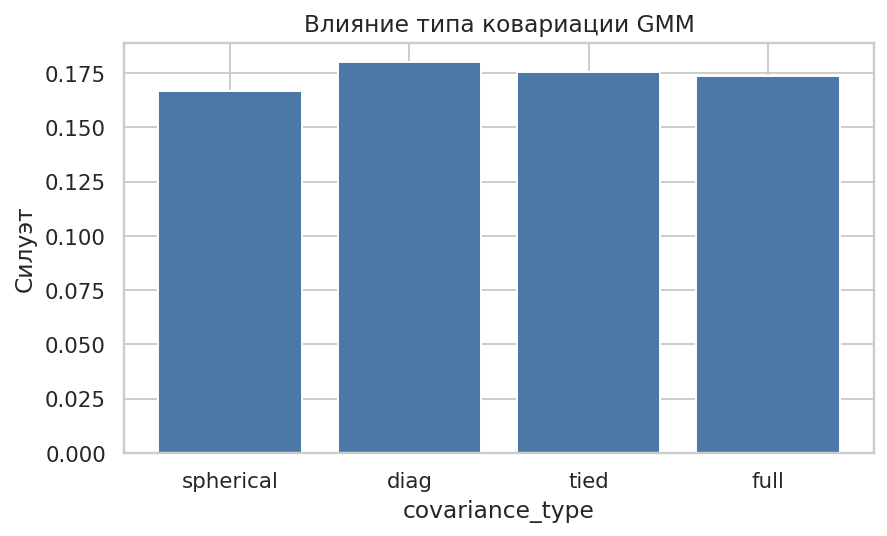

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(covariance_table.index, covariance_table["силуэт"], color="#4C78A8")
ax.set_ylabel("Силуэт")
ax.set_xlabel("covariance_type")
ax.set_title("Влияние типа ковариации GMM")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_gmm_covariance.png", bbox_inches="tight")
plt.show()


### Пояснение к влиянию параметров

- Число кластеров меняет и инерцию, и силуэт: это видно на графике подбора k. После выбранного k новые центры уменьшают инерцию медленнее.
- У GMM при фиксированном k = 2 сравнены `spherical`, `diag`, `tied` и `full`. Силуэт лучшего типа (diag) равен 0,180, худшего — 0,167.
- `spherical` заставляет все компоненты быть шарами, `diag` разрешает разный масштаб по осям без наклона, `tied` даёт одну общую форму всем группам, `full` оценивает отдельный эллипс на каждую.


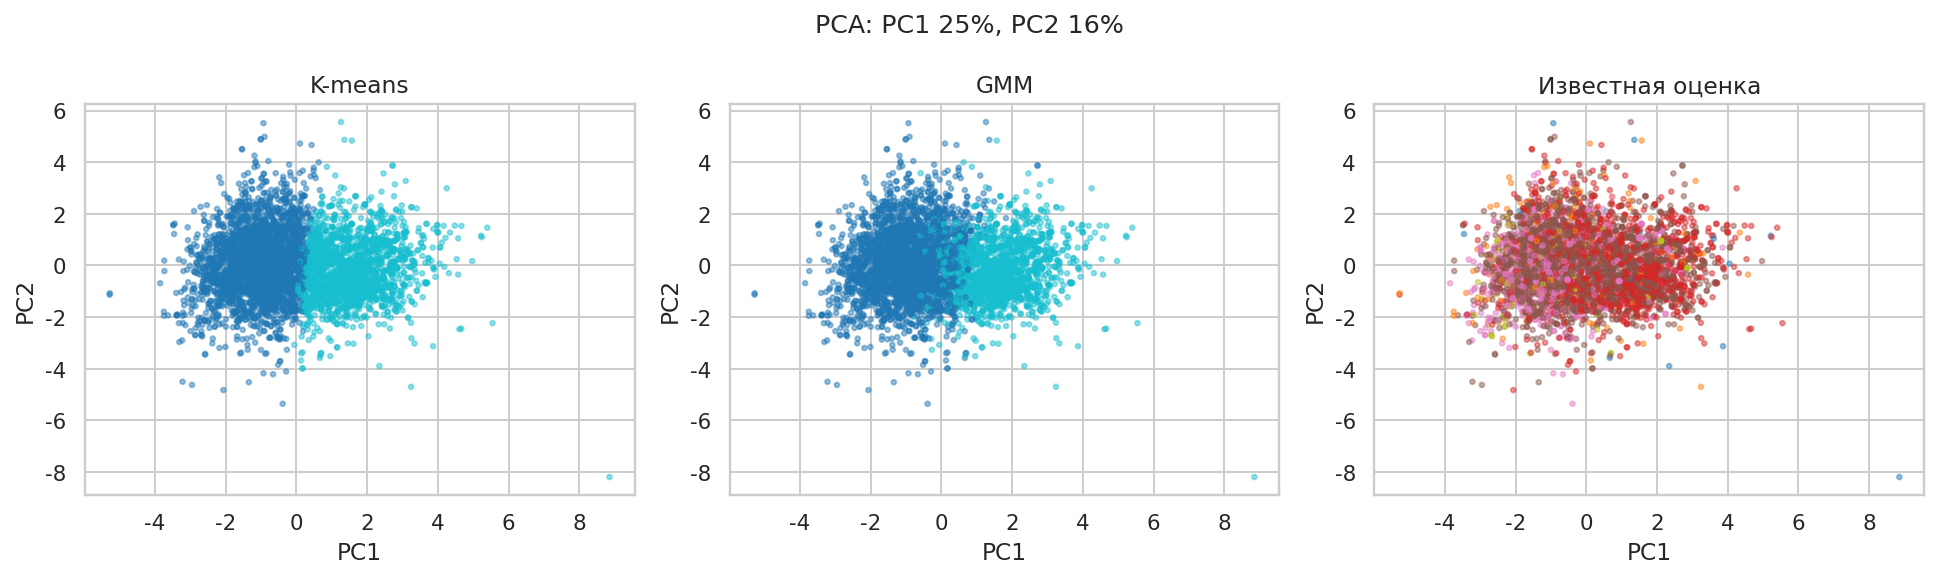

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy = pca.fit_transform(x_scaled)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
panels = (
    (kmeans_labels, "K-means"),
    (gmm_labels, "GMM"),
    (y.to_numpy(), "Известная оценка"),
)
for ax, (labels, title) in zip(axes, panels):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=6, alpha=0.45)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
fig.suptitle(f"PCA: PC1 {explained[0]:.0%}, PC2 {explained[1]:.0%}", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_pca_clusters.png", bbox_inches="tight")
plt.show()


### Пояснение к визуализации и центрам K-means

- Две первые главные компоненты сохраняют 24,6% и 15,8% дисперсии. На плоскости видны и разбиения алгоритмов, и известные оценки. Номера кластеров и баллы качества задаются независимо.
- Центры K-means переведены обратно из стандартизованного масштаба. По ним группы читаются так:

- Кластер 0: чаще всего оценка 6 (0,45 доли объектов), спирт в центре 11,15%, остаточный сахар 3,67.
- Кластер 1: чаще всего оценка 6 (0,44 доли объектов), спирт в центре 9,59%, остаточный сахар 10,35.

Соседние баллы химически близки, поэтому один кластер обычно собирает несколько соседних оценок, а не один балл.


latent=2, lr=0.001, l2=0.0: MSE=0.5636, silhouette=0.472
latent=2, lr=0.001, l2=0.0001: MSE=0.5672, silhouette=0.412
latent=2, lr=0.01, l2=0.0: MSE=0.5092, silhouette=0.351
latent=2, lr=0.01, l2=0.0001: MSE=0.4721, silhouette=0.473
latent=4, lr=0.001, l2=0.0: MSE=0.3950, silhouette=0.240
latent=4, lr=0.001, l2=0.0001: MSE=0.4099, silhouette=0.333
latent=4, lr=0.01, l2=0.0: MSE=0.2721, silhouette=0.236
latent=4, lr=0.01, l2=0.0001: MSE=0.2736, silhouette=0.271
latent=8, lr=0.001, l2=0.0: MSE=0.2183, silhouette=0.302
latent=8, lr=0.001, l2=0.0001: MSE=0.2415, silhouette=0.416
latent=8, lr=0.01, l2=0.0: MSE=0.0787, silhouette=0.310
latent=8, lr=0.01, l2=0.0001: MSE=0.0731, silhouette=0.246


,латентность,скорость,L2,MSE,силуэт в латентном пространстве
0,2,0.001,0.0000,0.5636,0.4725
1,2,0.001,0.0001,0.5672,0.4122
2,2,0.010,0.0000,0.5092,0.3509
3,2,0.010,0.0001,0.4721,0.4726
4,4,0.001,0.0000,0.3950,0.2404
5,4,0.001,0.0001,0.4099,0.3330
6,4,0.010,0.0000,0.2721,0.2360
7,4,0.010,0.0001,0.2736,0.2707
8,8,0.001,0.0000,0.2183,0.3016
9,8,0.001,0.0001,0.2415,0.4157


,k,силуэт в латентном пространстве
0,2,0.473
1,3,0.325


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
Автокодировщик + K-means,0.159,325.290,2.874,3.021,2.102,2.102,0.438,0.026,0.008,0.300
DEC,0.105,379.655,3.102,2.903,1.872,1.872,0.481,0.023,0.007,0.275


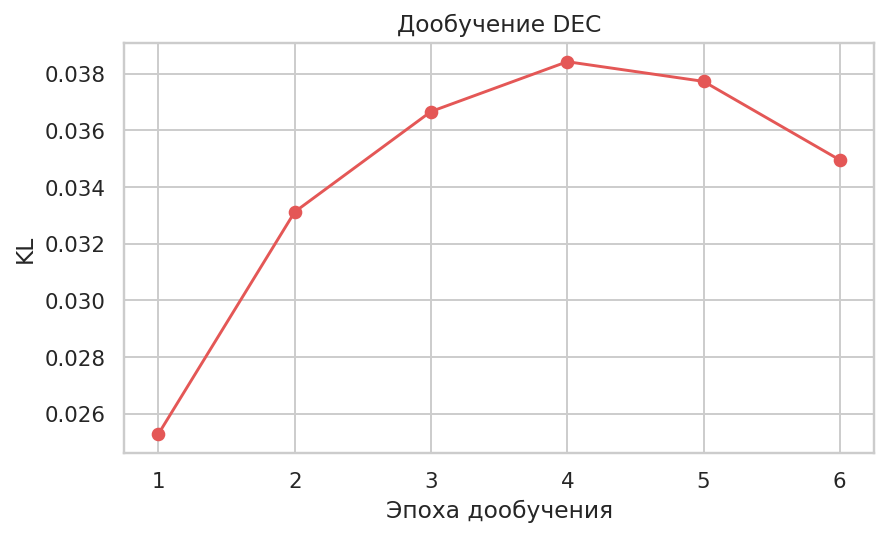

In [11]:
def build_autoencoder(latent_dim, l2):
    regularizer = tf.keras.regularizers.l2(l2) if l2 else None
    inputs = tf.keras.Input(shape=(x_scaled.shape[1],))
    hidden = tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=regularizer)(inputs)
    hidden = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(hidden)
    latent = tf.keras.layers.Dense(latent_dim, activation="linear", name="latent")(hidden)
    hidden = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(latent)
    hidden = tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=regularizer)(hidden)
    outputs = tf.keras.layers.Dense(x_scaled.shape[1], activation="linear")(hidden)
    autoencoder = tf.keras.Model(inputs, outputs)
    encoder = tf.keras.Model(inputs, latent)
    return autoencoder, encoder


def soft_assign(latent, centers, alpha=1.0):
    distance = tf.reduce_sum(tf.square(tf.expand_dims(latent, 1) - tf.expand_dims(centers, 0)), axis=2)
    weights = tf.pow(1.0 + distance / alpha, -(alpha + 1.0) / 2.0)
    return weights / tf.reduce_sum(weights, axis=1, keepdims=True)


def target_distribution(weights):
    frequency = tf.square(weights) / tf.reduce_sum(weights, axis=0, keepdims=True)
    return frequency / tf.reduce_sum(frequency, axis=1, keepdims=True)


def latent_silhouette(latent, n_clusters):
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE).fit_predict(latent)
    score = float(silhouette_score(latent, labels, sample_size=2000, random_state=RANDOM_STATE))
    return labels, score


grid_rows = []
trained = []
for latent_dim in (2, 4, 8):
    for learning_rate in (0.001, 0.01):
        for l2 in (0.0, 1e-4):
            autoencoder, encoder = build_autoencoder(latent_dim, l2)
            autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss="mse")
            history = autoencoder.fit(
                x_scaled, x_scaled, epochs=12, batch_size=256, validation_split=0.1, verbose=0
            )
            latent = encoder.predict(x_scaled, verbose=0)
            _, score = latent_silhouette(latent, best_k)
            row = {
                "латентность": latent_dim,
                "скорость": learning_rate,
                "L2": l2,
                "MSE": float(history.history["val_loss"][-1]),
                "силуэт в латентном пространстве": score,
            }
            grid_rows.append(row)
            trained.append((encoder, latent))
            print(
                f"latent={latent_dim}, lr={learning_rate}, l2={l2}: "
                f"MSE={row['MSE']:.4f}, silhouette={score:.3f}"
            )

grid_table = pd.DataFrame(grid_rows)
grid_table.to_csv(OUTPUT_DIR / "dec_grid.csv", index=False, encoding="utf-8-sig")
display(grid_table.round(4))
best_position = int(grid_table["силуэт в латентном пространстве"].idxmax())
best_row = grid_table.loc[best_position]
best_encoder, best_latent = trained[best_position]

k_candidates = sorted({max(2, best_k - 1), best_k, best_k + 1})
k_rows = []
for n_clusters in k_candidates:
    labels, score = latent_silhouette(best_latent, n_clusters)
    k_rows.append({"k": n_clusters, "силуэт в латентном пространстве": score, "метки": labels})
latent_k_table = pd.DataFrame([{key: value for key, value in row.items() if key != "метки"} for row in k_rows])
display(latent_k_table.round(3))
chosen_k_row = max(k_rows, key=lambda item: item["силуэт в латентном пространстве"])
deep_k = int(chosen_k_row["k"])
ae_labels = chosen_k_row["метки"]
ae_model = KMeans(n_clusters=deep_k, n_init=10, random_state=RANDOM_STATE).fit(best_latent)

centers = tf.Variable(ae_model.cluster_centers_.astype(np.float32))
optimizer = tf.keras.optimizers.Adam(float(best_row["скорость"]))
x_tensor = tf.constant(x_scaled.astype(np.float32))
dec_losses = []
for epoch in range(6):
    latent_now = best_encoder(x_tensor, training=False)
    target = tf.stop_gradient(target_distribution(soft_assign(latent_now, centers)))
    batches = tf.data.Dataset.from_tensor_slices((x_tensor, target)).batch(256)
    epoch_losses = []
    for batch_x, batch_target in batches:
        with tf.GradientTape() as tape:
            latent_batch = best_encoder(batch_x, training=True)
            weights = soft_assign(latent_batch, centers)
            loss = tf.reduce_mean(
                tf.reduce_sum(batch_target * tf.math.log((batch_target + 1e-8) / (weights + 1e-8)), axis=1)
            )
        variables = best_encoder.trainable_variables + [centers]
        optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
        epoch_losses.append(float(loss))
    dec_losses.append(float(np.mean(epoch_losses)))

final_weights = soft_assign(best_encoder(x_tensor, training=False), centers)
dec_labels = tf.argmax(final_weights, axis=1).numpy()

ae_space_centers = np.vstack([
    x_scaled[ae_labels == index].mean(axis=0) if np.any(ae_labels == index) else np.zeros(x_scaled.shape[1])
    for index in range(deep_k)
])
dec_space_centers = np.vstack([
    x_scaled[dec_labels == index].mean(axis=0) if np.any(dec_labels == index) else np.zeros(x_scaled.shape[1])
    for index in range(deep_k)
])
ae_metrics = clustering_metrics("Автокодировщик + K-means", ae_labels, ae_space_centers)
dec_metrics = clustering_metrics("DEC", dec_labels, dec_space_centers)
deep_metrics = pd.DataFrame([ae_metrics, dec_metrics]).set_index("Модель")
deep_metrics.to_csv(OUTPUT_DIR / "metrics_deep.csv", encoding="utf-8-sig")
display(deep_metrics.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(1, len(dec_losses) + 1), dec_losses, marker="o", color="#E45756")
ax.set_xlabel("Эпоха дообучения")
ax.set_ylabel("KL")
ax.set_title("Дообучение DEC")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "09_dec_loss.png", bbox_inches="tight")
plt.show()


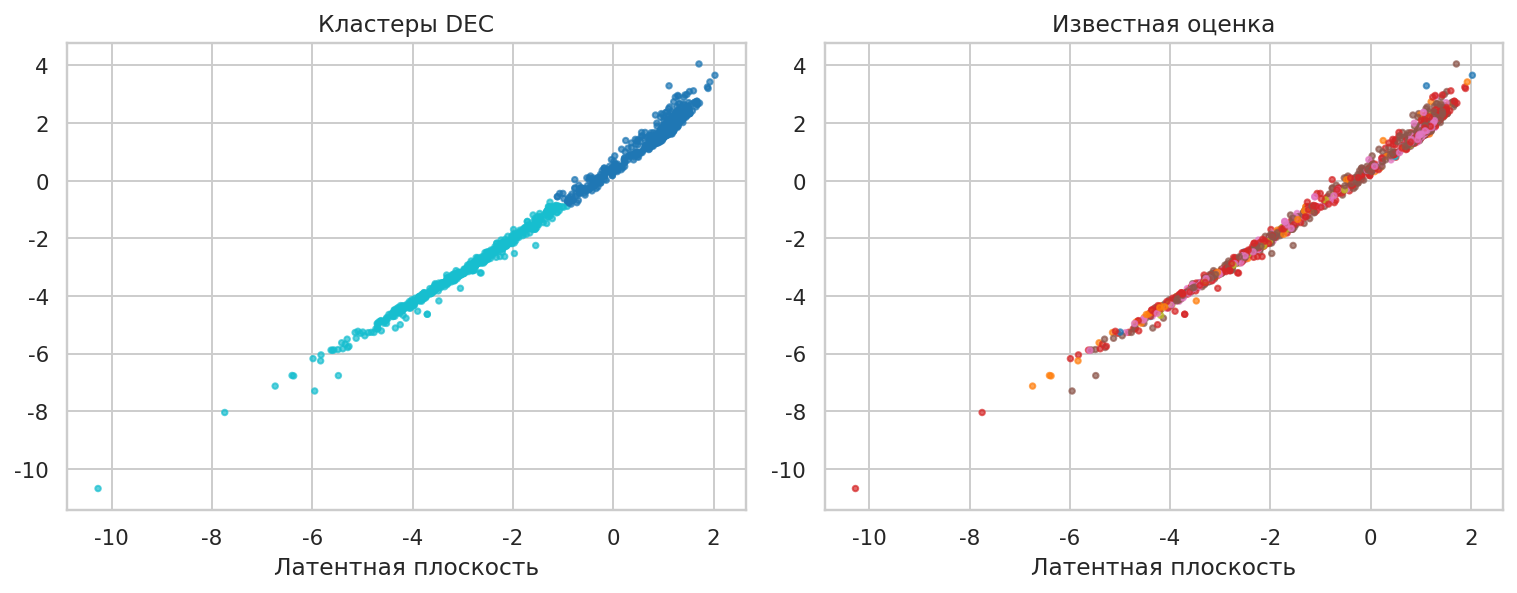

quality,оценка 3,оценка 4,оценка 5,оценка 6,оценка 7,оценка 8,оценка 9
кластер DEC,,,,,,,
0,13,81,1026,1654,591,115,4
1,7,82,431,544,289,60,1


In [12]:
sample_index = np.random.default_rng(RANDOM_STATE).choice(len(x_scaled), size=2000, replace=False)
latent_sample = best_encoder.predict(x_scaled[sample_index], verbose=0)
if latent_sample.shape[1] == 2:
    embedding = latent_sample
    embedding_name = "Латентная плоскость"
else:
    embedding = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        max_iter=750,
        random_state=RANDOM_STATE,
    ).fit_transform(latent_sample)
    embedding_name = "t-SNE латентного пространства"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(embedding[:, 0], embedding[:, 1], c=dec_labels[sample_index], cmap="tab10", s=8, alpha=0.7)
axes[0].set_title("Кластеры DEC")
axes[1].scatter(embedding[:, 0], embedding[:, 1], c=y.iloc[sample_index], cmap="tab10", s=8, alpha=0.7)
axes[1].set_title("Известная оценка")
for ax in axes:
    ax.set_xlabel(embedding_name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "10_latent_space.png", bbox_inches="tight")
plt.show()

dec_crosstab = pd.crosstab(
    pd.Series(dec_labels, name="кластер DEC"),
    y.map(lambda score: f"оценка {score}"),
)
dec_crosstab.to_csv(OUTPUT_DIR / "dec_crosstab.csv", encoding="utf-8-sig")
display(dec_crosstab)


### Пояснение к глубокой кластеризации DEC

- **Зачем.** Классические методы работают в исходных 10 признаках. DEC сначала сжимает их автокодировщиком, а затем уточняет центры в латентном пространстве.
- **Архитектура.** Полносвязная сеть 10 → 32 → 16 → латентный слой → 16 → 32 → 10. Скрытые слои с ReLU, латентный и выходной слои линейные: концентрации не нужно обрезать положительной активацией.
- **Функции потерь.** Предобучение минимизирует MSE: выход должен восстановить стандартизованные измерения. Дообучение DEC минимизирует KL между целевым распределением P и мягкими назначениями Стьюдента Q. P строится из Q и на каждом шаге заморожено, как в работе Xie, Girshick и Farhadi (2016). Коэффициент L2 штрафует веса.
- **Подбор.** Сетка: латентность 2, 4 и 8; скорость обучения 0,001 и 0,01; L2 = 0 и 0,0001. Критерий — силуэт K-means в латентном пространстве, без подглядывания в оценку. Лучшая предобученная сеть: латентность 2, скорость 0,010, L2 0,0001. Число кластеров в латентном пространстве выбрано из окрестности классического k и равно **2**.
- Затем 6 эпох DEC двигают и кодировщик, и центры. Метрики DEC и автокодировщика с K-means посчитаны в том же исходном пространстве, что и у классических методов.
- Автокодировщик + K-means: силуэт 0,159, ARI 0,026.
- DEC: силуэт 0,105, ARI 0,023.


,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,
K-means,0.180,1033.341,1.998,2.683,2.686,2.686,0.506,0.024,0.044,0.260
GMM,0.180,965.106,2.032,2.705,2.602,2.602,0.502,0.027,0.053,0.266
Автокодировщик + K-means,0.159,325.290,2.874,3.021,2.102,2.102,0.438,0.026,0.008,0.300
DEC,0.105,379.655,3.102,2.903,1.872,1.872,0.481,0.023,0.007,0.275


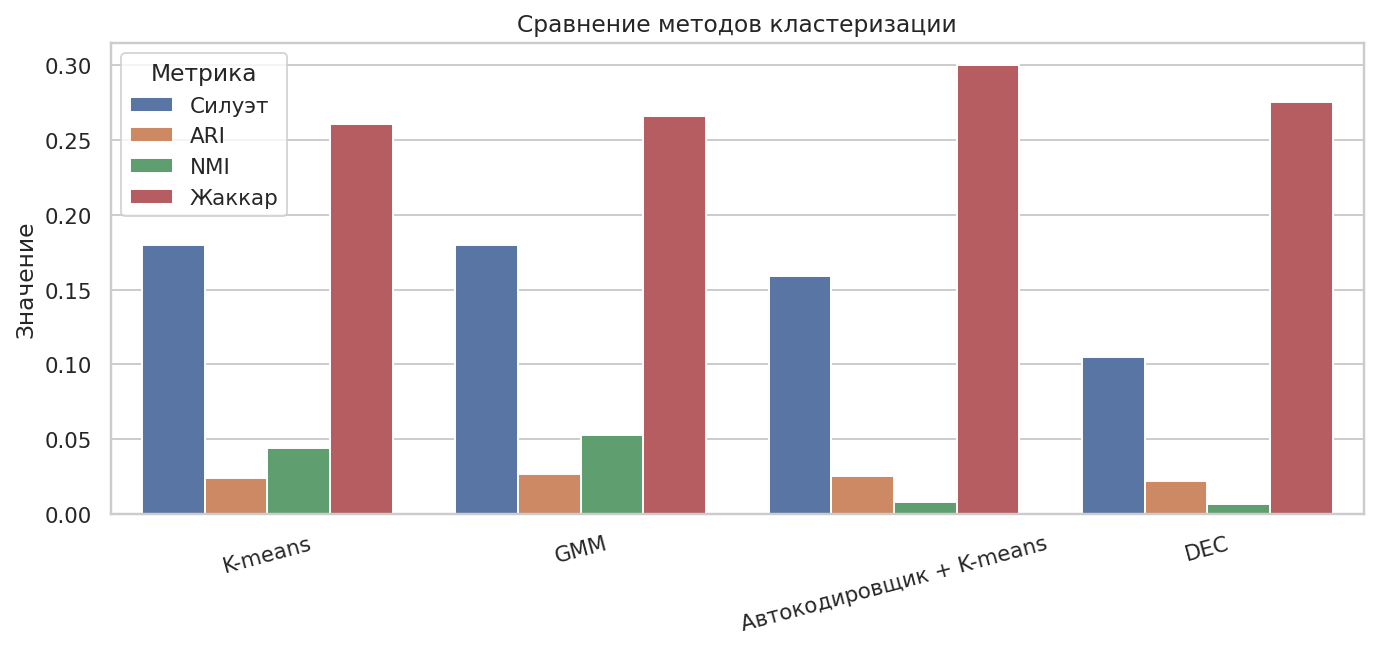

In [13]:
final_table = pd.concat([metrics, deep_metrics])
final_table.to_csv(OUTPUT_DIR / "metrics_all.csv", encoding="utf-8-sig")
display(final_table.round(3))

plot_frame = final_table.reset_index().melt(
    id_vars="Модель",
    value_vars=["Силуэт", "ARI", "NMI", "Жаккар"],
    var_name="Метрика",
    value_name="Значение",
)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=plot_frame, x="Модель", y="Значение", hue="Метрика", ax=ax)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
ax.set_title("Сравнение методов кластеризации")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "11_comparison.png", bbox_inches="tight")
plt.show()


---
## Сравнительный анализ

По силуэту в исходном пространстве лучше **GMM** (0,180). По согласованности с оценкой качества (ARI) лучше **GMM** (0,027).

K-means ищет компактные группы вокруг центров. GMM с ковариацией `diag` разрешает этим группам быть эллипсами. Глубокая модель добавляет нелинейное сжатие. ARI глубокой модели ниже лучшего классического результата на 0,001. Для этой таблицы глубокая кластеризация не нужна: признаки уже числовые и их немного, автокодировщик сжимает почти ту же геометрию, которую видят K-means и GMM.

Оценка качества — это не отдельный сорт: баллы 5, 6 и 7 химически пересекаются. Силуэт около 0,18, а расстояние внутри кластера почти равно расстоянию между центрами, так что группы разделены слабо. Оба кластера чаще всего содержат оценку 6 и отличаются составом: один суше и крепче (сахар 3,67, спирт 11,15%), другой слаще и легче (сахар 10,35, спирт 9,59%). С баллами качества это почти не совпадает.

## Заключение

1. **Данные.** White Wine Quality: 4898 образцов белого вина, 11 химических признаков, пропусков нет. Оценка отложена и используется только как внешняя метка.
2. **Распределения.** Нормальность не выполняется у 11 признаков. Крайние значения по IQR, прежде всего у «Лимонная кислота», оставлены в выборке.
3. **Признаки и масштаб.** После удаления дублей с |r| > 0,80 осталось 10 признаков. StandardScaler выравнивает диоксид серы, сахар и спирт.
4. **Число кластеров.** Локоть даёт k = 2, максимум силуэта — k = 2. В расчётах используется k = 2.
5. **Классические методы.** K-means и GMM (`diag`) дают близкий силуэт около 0,180. Совпадение с семью баллами слабое: ARI около 0,03. Кластеры читаются как сухой крепкий и сладкий лёгкий стили, а не как отдельные оценки.
6. **Параметры.** Тип ковариации GMM меняет силуэт; выбран `diag`. Число кластеров сильнее всего влияет на инерцию до выбранного k.
7. **DEC.** Лучшая сеть имеет латентность 2, скорость 0,010 и L2 0,0001, число кластеров 2. ARI глубокой модели ниже лучшего классического результата на 0,001. Для этой таблицы глубокая кластеризация не нужна: признаки уже числовые и их немного, автокодировщик сжимает почти ту же геометрию, которую видят K-means и GMM.
8. **Итог.** Для этих химических измерений достаточно K-means или GMM. Глубокая кластеризация уместнее там, где признаки сырые и очень большой размерности.

---
## Список использованных источников

1. White Wine Quality // Kaggle. URL: https://www.kaggle.com/datasets/piyushagni5/white-wine-quality
2. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009.
3. Wine Quality // UCI Machine Learning Repository. URL: https://archive.ics.uci.edu/dataset/186/wine+quality
4. *Hastie T., Tibshirani R., Friedman J.* The Elements of Statistical Learning. 2nd ed. Springer, 2009.
5. Xie J., Girshick R., Farhadi A. Unsupervised Deep Embedding for Clustering Analysis // ICML. 2016.
6. Документация scikit-learn: K-means, Gaussian mixture, метрики кластеризации. URL: https://scikit-learn.org/stable/modules/clustering.html
7. Документация TensorFlow Keras: https://www.tensorflow.org/guide/keras

---
## Приложение

Полный листинг программы приведён в кодовых ячейках этого отчёта. Отдельный файл сценария не используется: ноутбук и есть воспроизводимый код, от загрузки данных до сравнения метрик.
